# Board Games Data Mining
## 5. Regression

This notebook is a cleaned and reorganized version of the original regression work.

The analysis follows:

1. Exploratory all-vs-all screening
2. Simple regression: `AvgPlaytime → GameWeight`
3. Multiple regression: prediction of `GameWeight`
4. Comparison WITH vs WITHOUT `AvgPlaytime`
5. Multicollinearity and predictor importance
6. Final discussion

The models considered are:
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor

### 5.0 Setup and Data Loading


In [1]:
from pathlib import Path
from itertools import permutations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
candidate_paths = [
    Path("DM1_game_dataset_prepared.csv"),
    Path("data/DM1_game_dataset_prepared.csv"),
    Path("DM1_game_dataset_cleaned_5_ml.csv"),
    Path("data/DM1_game_dataset_cleaned_5_ml.csv"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Regression dataset not found. Expected 'DM1_game_dataset_prepared.csv' "
        "in the current folder or inside 'data/'."
    )

df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Initial shape:", df.shape)
display(df.head())


Loaded: DM1_game_dataset_prepared.csv
Initial shape: (20671, 24)


,YearPublished,AvgPlaytime,GameWeight,MfgAgeRec,MinPlayers,MaxPlayers,Ranking,Rating,SemanticString,NumOwned,...,IsReimplementation,Kickstarted,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
0,2014,3.433987,1.8333,15.0,2,4,0.499238,1,assassin s creed arena game description publis...,6.270988,...,False,False,False,False,False,False,False,False,False,False
1,2021,2.917771,1.0000,8.0,2,5,0.499238,2,bag of chips bag chip party game face crucial ...,4.290459,...,False,False,False,False,False,False,False,False,False,False
2,2020,4.510860,3.6667,12.0,1,5,0.499238,3,gùgōng deluxe big box big box contain componen...,6.727432,...,False,False,False,False,False,False,False,False,False,False
3,2004,3.044522,1.3077,10.0,2,2,0.499238,1,letterflip publisherthe reveal game secret wor...,5.043425,...,False,False,False,False,False,False,False,False,False,False
4,2019,2.917771,1.5000,8.0,2,4,0.499238,2,treasures of cibola rescue mayan treasure easy...,5.342334,...,False,False,False,False,False,False,False,False,False,False


### Regression variables

This is an exploratory screening over **eight numerical variables**, corresponding to 56 ordered predictor-target pairs. `Rating` is intentionally excluded from the regression analysis because it is the categorical target of the classification section.

The operational filters used in the regression are retained:
- `YearPublished >= 1949`
- `MaxPlayers <= 30`

Missing values are removed only from the variables actually used for regression.

In [3]:
REGRESSION_VARIABLES = [
    "YearPublished",
    "MfgAgeRec",
    "MinPlayers",
    "MaxPlayers",
    "AvgPlaytime",
    "GameWeight",
    "NumOwned",
    "NumDemand",
]

missing = [c for c in REGRESSION_VARIABLES if c not in df.columns]
if missing:
    raise KeyError(f"Missing regression columns: {missing}")

df_reg = df.loc[
    (df["YearPublished"] >= 1949) &
    (df["MaxPlayers"] <= 30),
    REGRESSION_VARIABLES
].dropna().copy()

print("Rows used for regression:", len(df_reg))
print("Variables:", len(REGRESSION_VARIABLES))
display(df_reg.describe().T)


Rows used for regression: 20671
Variables: 8


,count,mean,std,min,25%,50%,75%,max
YearPublished,20671.0,2006.652363,13.913514,1949.000000,2002.000000,2011.000000,2017.000000,2021.000000
MfgAgeRec,20671.0,10.332688,2.786944,1.000000,8.000000,10.000000,12.000000,25.000000
MinPlayers,20671.0,2.009482,0.684621,1.000000,2.000000,2.000000,2.000000,10.000000
MaxPlayers,20671.0,4.948866,3.530837,1.000000,4.000000,4.000000,6.000000,30.000000
AvgPlaytime,20671.0,3.843025,0.886317,0.693147,3.258097,3.828641,4.330733,11.002117
GameWeight,20671.0,2.032778,0.798683,1.000000,1.352900,2.000000,2.548400,5.000000
NumOwned,20671.0,6.082067,1.369172,1.098612,5.081404,5.855072,6.874198,12.022739
NumDemand,20671.0,4.139220,1.614701,0.000000,2.995732,3.970292,5.135798,9.958402


## Exploratory all-vs-all screening

We tested many predictor-target combinations but in this version we avoided generating hundreds of image files.

The full nonlinear screening can take some time because Random Forest and Gradient Boosting are trained for every ordered pair, so it is controlled by a flag.

In [4]:
RANDOM_STATE = 42
TEST_SIZE = 0.30

DT_PARAMS = {
    "max_depth": 7,
    "min_samples_leaf": 50,
    "min_samples_split": 100,
    "random_state": RANDOM_STATE,
}

RF_PARAMS = {
    "n_estimators": 300,
    "max_depth": None,
    "min_samples_leaf": 50,
    "min_samples_split": 100,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

GB_PARAMS = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 3,
    "min_samples_leaf": 50,
    "subsample": 0.8,
    "random_state": RANDOM_STATE,
}

def build_models():
    return {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(**DT_PARAMS),
        "Random Forest": RandomForestRegressor(**RF_PARAMS),
        "Gradient Boosting": GradientBoostingRegressor(**GB_PARAMS),
    }


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2": r2_score(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
    }


In [5]:
RUN_FULL_ALL_VS_ALL = True

def run_all_vs_all(data, variables, include_nonlinear=True):
    rows = []

    model_names = (
        list(build_models().keys())
        if include_nonlinear
        else ["Linear Regression"]
    )

    for target, feature in permutations(variables, 2):
        pair = data[[feature, target]].dropna()

        X = pair[[feature]]
        y = pair[target]

        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
        )

        models = build_models()

        for model_name in model_names:
            model = models[model_name]
            model.fit(X_train, y_train)
            pred = model.predict(X_test)

            row = {
                "Target": target,
                "Feature": feature,
                "Model": model_name,
                "N": len(pair),
            }
            row.update(regression_metrics(y_test, pred))
            rows.append(row)

    return pd.DataFrame(rows).sort_values("R2", ascending=False)


if RUN_FULL_ALL_VS_ALL:
    screening_results = run_all_vs_all(
        df_reg,
        REGRESSION_VARIABLES,
        include_nonlinear=True,
    )

    print("Ordered predictor-target pairs:", 8 * 7)
    display(screening_results.head(20))
else:
    print(
        "Full all-vs-all screening skipped. "
        "Set RUN_FULL_ALL_VS_ALL = True to reproduce it."
    )


Ordered predictor-target pairs: 56


,Target,Feature,Model,N,R2,MSE,RMSE
195,NumOwned,NumDemand,Gradient Boosting,20671,0.677841,0.614099,0.783645
194,NumOwned,NumDemand,Random Forest,20671,0.676990,0.615721,0.784679
193,NumOwned,NumDemand,Decision Tree,20671,0.676385,0.616874,0.785414
223,NumDemand,NumOwned,Gradient Boosting,20671,0.659650,0.906305,0.952000
221,NumDemand,NumOwned,Decision Tree,20671,0.657141,0.912988,0.955504
222,NumDemand,NumOwned,Random Forest,20671,0.656065,0.915851,0.957001
192,NumOwned,NumDemand,Linear Regression,20671,0.645674,0.675417,0.821838
220,NumDemand,NumOwned,Linear Regression,20671,0.645517,0.943941,0.971566
157,GameWeight,AvgPlaytime,Decision Tree,20671,0.546448,0.292176,0.540533
159,GameWeight,AvgPlaytime,Gradient Boosting,20671,0.546364,0.292229,0.540582


## 5.1 Simple Regression — `AvgPlaytime → GameWeight`

Although the exploratory screening identifies a stronger market/popularity relationship between `NumDemand` and `NumOwned`, we focused on `AvgPlaytime → GameWeight` because duration and perceived complexity represent distinct and more interpretable domains.

The same train/test split is used for all four regressors.

In [6]:
SIMPLE_FEATURE = "AvgPlaytime"
TARGET = "GameWeight"

simple_df = df_reg[[SIMPLE_FEATURE, TARGET]].dropna()

X_simple = simple_df[[SIMPLE_FEATURE]]
y_simple = simple_df[TARGET]

X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple,
    y_simple,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

simple_models = build_models()
simple_results = []
fitted_simple_models = {}

for model_name, model in simple_models.items():
    model.fit(X_simple_train, y_simple_train)
    pred = model.predict(X_simple_test)

    row = {
        "Model": model_name,
        "X": SIMPLE_FEATURE,
        "Y": TARGET,
    }
    row.update(regression_metrics(y_simple_test, pred))

    if model_name == "Linear Regression":
        row["Coefficient"] = model.coef_[0]
        row["Intercept"] = model.intercept_
    else:
        row["Coefficient"] = np.nan
        row["Intercept"] = np.nan

    simple_results.append(row)
    fitted_simple_models[model_name] = model

simple_results = pd.DataFrame(simple_results).sort_values(
    "R2",
    ascending=False,
)

display(simple_results)


,Model,X,Y,R2,MSE,RMSE,Coefficient,Intercept
1,Decision Tree,AvgPlaytime,GameWeight,0.546448,0.292176,0.540533,NaN,NaN
3,Gradient Boosting,AvgPlaytime,GameWeight,0.546364,0.292229,0.540582,NaN,NaN
2,Random Forest,AvgPlaytime,GameWeight,0.546348,0.292240,0.540592,NaN,NaN
0,Linear Regression,AvgPlaytime,GameWeight,0.513936,0.313119,0.559571,0.644738,-0.447199


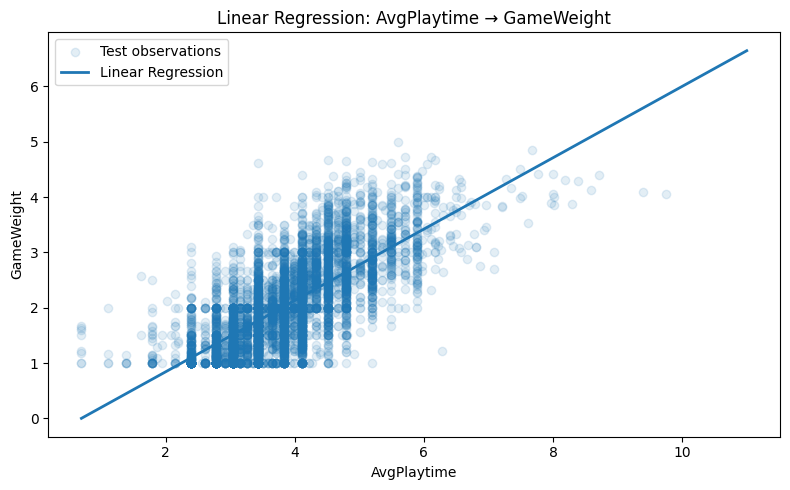

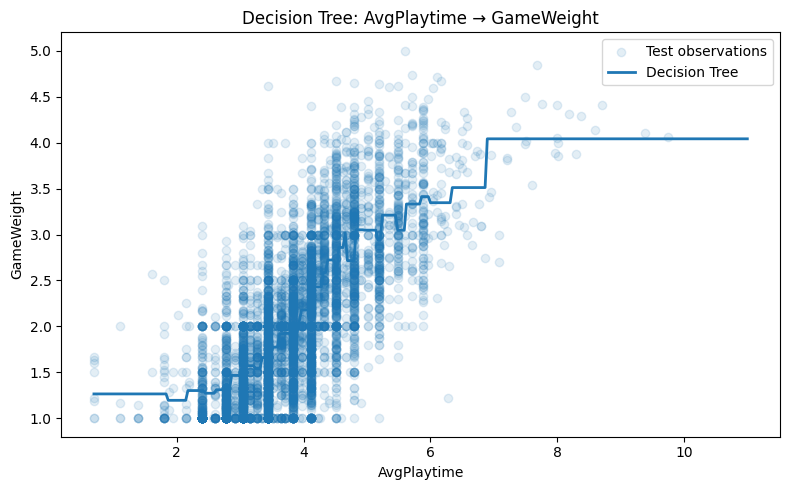

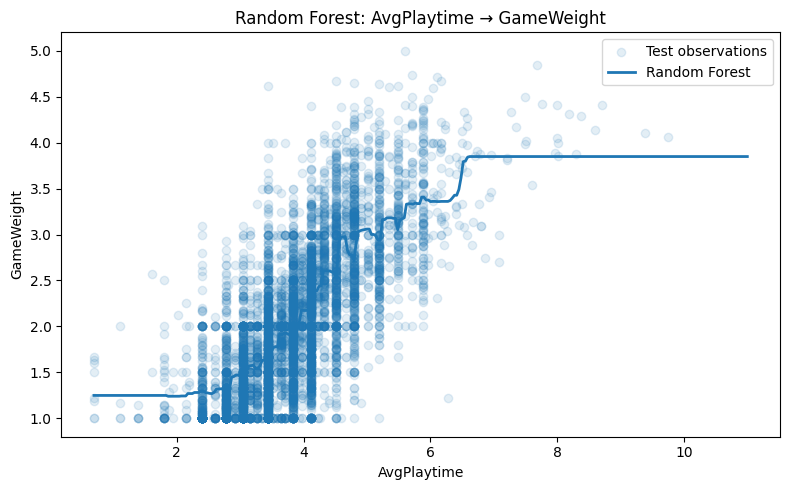

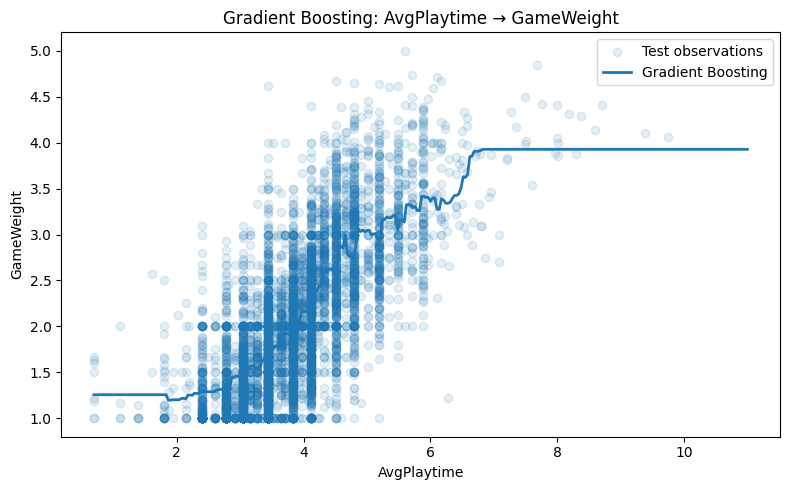

In [7]:
# Visual comparison of the fitted simple-regression functions.

x_grid = np.linspace(
    X_simple[SIMPLE_FEATURE].min(),
    X_simple[SIMPLE_FEATURE].max(),
    300,
)

for model_name, model in fitted_simple_models.items():
    grid_df = pd.DataFrame({SIMPLE_FEATURE: x_grid})
    grid_pred = model.predict(grid_df)

    plt.figure(figsize=(8, 5))
    plt.scatter(
        X_simple_test[SIMPLE_FEATURE],
        y_simple_test,
        alpha=0.12,
        label="Test observations",
    )
    plt.plot(
        x_grid,
        grid_pred,
        linewidth=2,
        label=model_name,
    )
    plt.xlabel(SIMPLE_FEATURE)
    plt.ylabel(TARGET)
    plt.title(f"{model_name}: {SIMPLE_FEATURE} → {TARGET}")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 5.2 Multiple Regression

The target remains `GameWeight`.

The final predictor set is:

- `YearPublished`
- `MfgAgeRec`
- `MinPlayers`
- `MaxPlayers`
- `NumOwned`
- `NumDemand`

and the models are compared in two configurations:

- **WITH AvgPlaytime**
- **WITHOUT AvgPlaytime**

This directly quantifies the contribution of gameplay duration to the prediction of perceived complexity.

In [8]:
BASE_PREDICTORS = [
    "YearPublished",
    "MfgAgeRec",
    "MinPlayers",
    "MaxPlayers",
    "NumOwned",
    "NumDemand",
]

FEATURES_WITH = ["AvgPlaytime"] + BASE_PREDICTORS
FEATURES_WITHOUT = BASE_PREDICTORS.copy()


def run_multiple_regression(data, features, setting_name):
    tmp = data[[TARGET] + features].dropna()

    X = tmp[features]
    y = tmp[TARGET]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
    )

    rows = []
    fitted = {}

    for model_name, model in build_models().items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        row = {
            "Setting": setting_name,
            "Model": model_name,
            "Y": TARGET,
            "N": len(tmp),
        }
        row.update(regression_metrics(y_test, pred))

        rows.append(row)
        fitted[model_name] = (model, X_test, y_test)

    return pd.DataFrame(rows), fitted


results_with, models_with = run_multiple_regression(
    df_reg,
    FEATURES_WITH,
    "WITH AvgPlaytime",
)

results_without, models_without = run_multiple_regression(
    df_reg,
    FEATURES_WITHOUT,
    "WITHOUT AvgPlaytime",
)

multiple_results = pd.concat(
    [results_with, results_without],
    ignore_index=True,
).sort_values(
    ["Setting", "R2"],
    ascending=[True, False],
)

display(multiple_results)


,Setting,Model,Y,N,R2,MSE,RMSE
3,WITH AvgPlaytime,Gradient Boosting,GameWeight,20671,0.677517,0.207741,0.455786
2,WITH AvgPlaytime,Random Forest,GameWeight,20671,0.663704,0.216640,0.465446
1,WITH AvgPlaytime,Decision Tree,GameWeight,20671,0.644072,0.229286,0.478839
0,WITH AvgPlaytime,Linear Regression,GameWeight,20671,0.616801,0.246854,0.496844
7,WITHOUT AvgPlaytime,Gradient Boosting,GameWeight,20671,0.524684,0.306196,0.553349
6,WITHOUT AvgPlaytime,Random Forest,GameWeight,20671,0.504373,0.319279,0.565048
5,WITHOUT AvgPlaytime,Decision Tree,GameWeight,20671,0.469555,0.341709,0.584559
4,WITHOUT AvgPlaytime,Linear Regression,GameWeight,20671,0.417267,0.375393,0.612693


### Multicollinearity check (VIF)

VIF is calculated on the training portion only.  
A value substantially below 10 is generally interpreted as evidence that multicollinearity is not severe enough to invalidate coefficient interpretation.

In [9]:
def compute_vif(data, features):
    tmp = data[[TARGET] + features].dropna()
    X = tmp[features]
    y = tmp[TARGET]

    X_train, _, _, _ = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
    )

    rows = []

    for feature in features:
        other_features = [f for f in features if f != feature]

        model = LinearRegression()
        model.fit(X_train[other_features], X_train[feature])

        r2 = model.score(
            X_train[other_features],
            X_train[feature],
        )

        vif = np.inf if np.isclose(1 - r2, 0) else 1 / (1 - r2)

        rows.append({
            "Feature": feature,
            "VIF": vif,
        })

    return pd.DataFrame(rows).sort_values(
        "VIF",
        ascending=False,
    )


vif_with = compute_vif(df_reg, FEATURES_WITH)
vif_with.insert(0, "Setting", "WITH AvgPlaytime")

vif_without = compute_vif(df_reg, FEATURES_WITHOUT)
vif_without.insert(0, "Setting", "WITHOUT AvgPlaytime")

vif_results = pd.concat(
    [vif_with, vif_without],
    ignore_index=True,
)

display(vif_results)


,Setting,Feature,VIF
0,WITH AvgPlaytime,NumDemand,3.405916
1,WITH AvgPlaytime,NumOwned,2.970082
2,WITH AvgPlaytime,AvgPlaytime,1.546078
3,WITH AvgPlaytime,MfgAgeRec,1.466956
4,WITH AvgPlaytime,YearPublished,1.261876
5,WITH AvgPlaytime,MinPlayers,1.127205
6,WITH AvgPlaytime,MaxPlayers,1.121106
7,WITHOUT AvgPlaytime,NumDemand,3.311356
8,WITHOUT AvgPlaytime,NumOwned,2.943688
9,WITHOUT AvgPlaytime,YearPublished,1.149661


### Predictor importance

Permutation importance is computed on the test set for the nonlinear models.  
This is useful for interpreting which variables act as the main alternatives when `AvgPlaytime` is removed.

In [10]:
def permutation_importance_table(
    fitted_models,
    features,
    setting_name,
    n_repeats=10,
):
    rows = []

    for model_name, (model, X_test, y_test) in fitted_models.items():
        importance = permutation_importance(
            model,
            X_test,
            y_test,
            scoring="r2",
            n_repeats=n_repeats,
            random_state=RANDOM_STATE,
        )

        for feature, mean_imp, std_imp in zip(
            features,
            importance.importances_mean,
            importance.importances_std,
        ):
            rows.append({
                "Setting": setting_name,
                "Model": model_name,
                "Feature": feature,
                "Importance_mean": mean_imp,
                "Importance_std": std_imp,
            })

    return pd.DataFrame(rows)


importance_results = pd.concat([
    permutation_importance_table(
        models_with,
        FEATURES_WITH,
        "WITH AvgPlaytime",
    ),
    permutation_importance_table(
        models_without,
        FEATURES_WITHOUT,
        "WITHOUT AvgPlaytime",
    ),
], ignore_index=True)

for setting in ["WITH AvgPlaytime", "WITHOUT AvgPlaytime"]:
    print(f"\n{setting}")
    for model_name in build_models().keys():
        print(f"\n{model_name}")
        display(
            importance_results[
                (importance_results["Setting"] == setting) &
                (importance_results["Model"] == model_name)
            ]
            .sort_values("Importance_mean", ascending=False)
            .head(7)
        )



WITH AvgPlaytime

Linear Regression


,Setting,Model,Feature,Importance_mean,Importance_std
0,WITH AvgPlaytime,Linear Regression,AvgPlaytime,0.611721,0.011126
6,WITH AvgPlaytime,Linear Regression,NumDemand,0.242336,0.004058
5,WITH AvgPlaytime,Linear Regression,NumOwned,0.067735,0.001566
2,WITH AvgPlaytime,Linear Regression,MfgAgeRec,0.060158,0.001500
4,WITH AvgPlaytime,Linear Regression,MaxPlayers,0.019074,0.002008
3,WITH AvgPlaytime,Linear Regression,MinPlayers,0.008102,0.000891
1,WITH AvgPlaytime,Linear Regression,YearPublished,0.001302,0.000416



Decision Tree


,Setting,Model,Feature,Importance_mean,Importance_std
7,WITH AvgPlaytime,Decision Tree,AvgPlaytime,0.656176,0.010699
9,WITH AvgPlaytime,Decision Tree,MfgAgeRec,0.126176,0.005752
13,WITH AvgPlaytime,Decision Tree,NumDemand,0.076022,0.002674
11,WITH AvgPlaytime,Decision Tree,MaxPlayers,0.066425,0.003332
10,WITH AvgPlaytime,Decision Tree,MinPlayers,0.005227,0.000479
8,WITH AvgPlaytime,Decision Tree,YearPublished,0.003095,0.000860
12,WITH AvgPlaytime,Decision Tree,NumOwned,0.000796,0.000451



Random Forest


...

,Setting,Model,Feature,Importance_mean,Importance_std
35,WITHOUT AvgPlaytime,Decision Tree,MfgAgeRec,0.569404,0.008735
39,WITHOUT AvgPlaytime,Decision Tree,NumDemand,0.221394,0.004546
37,WITHOUT AvgPlaytime,Decision Tree,MaxPlayers,0.086560,0.004694
34,WITHOUT AvgPlaytime,Decision Tree,YearPublished,0.041225,0.005746
36,WITHOUT AvgPlaytime,Decision Tree,MinPlayers,0.012899,0.001337
38,WITHOUT AvgPlaytime,Decision Tree,NumOwned,0.011424,0.002853



Random Forest


,Setting,Model,Feature,Importance_mean,Importance_std
41,WITHOUT AvgPlaytime,Random Forest,MfgAgeRec,0.560477,0.008318
45,WITHOUT AvgPlaytime,Random Forest,NumDemand,0.259236,0.004078
43,WITHOUT AvgPlaytime,Random Forest,MaxPlayers,0.078946,0.002824
40,WITHOUT AvgPlaytime,Random Forest,YearPublished,0.047232,0.004151
44,WITHOUT AvgPlaytime,Random Forest,NumOwned,0.035583,0.001935
42,WITHOUT AvgPlaytime,Random Forest,MinPlayers,0.012363,0.001301



Gradient Boosting


,Setting,Model,Feature,Importance_mean,Importance_std
47,WITHOUT AvgPlaytime,Gradient Boosting,MfgAgeRec,0.535592,0.009484
51,WITHOUT AvgPlaytime,Gradient Boosting,NumDemand,0.430122,0.006032
50,WITHOUT AvgPlaytime,Gradient Boosting,NumOwned,0.104452,0.002796
49,WITHOUT AvgPlaytime,Gradient Boosting,MaxPlayers,0.064274,0.002565
46,WITHOUT AvgPlaytime,Gradient Boosting,YearPublished,0.062781,0.003400
48,WITHOUT AvgPlaytime,Gradient Boosting,MinPlayers,0.014255,0.001561
